# DC Exception Copilot - walkthrough

An agentic RAG assistant for warehouse exception handling. This notebook **imports the
project's modules** (the real logic lives in `src/copilot/`, with tests) and walks through
what each build step produces.

| Step | What it builds | Status |
|---|---|---|
| 1 | Download free regulations + GS1 standards | done |
| 2 | Structure-aware chunking with exact citations | done |
| 3 | A synthetic distribution center (database + SOPs + SDS + incidents) | done |
| 4 | Hybrid retrieval (BM25 + vectors), evaluation and LangSmith tracing | done |
| 5 | Deterministic tools: read-only SQL, hazmat table, segregation, departure risk | done |
| 6 | LangGraph agent with verified citations and human approval | done |
| 7 | Agent evaluation: 36 cases, code checks + LLM judge, 64% -> 87% | done |
| 8-10 | API + UI, guardrails, CI | coming |

> Run from the project root after the quickstart in the README. Cells that need an OpenAI key
> fall back to keyword search when no key is configured.

In [1]:
import json
import sqlite3
import warnings
from collections import Counter

import matplotlib.pyplot as plt
import pandas as pd

from copilot.config import DATA_DIR, PROCESSED_DIR, RAW_DIR, settings
from copilot.observability import setup_tracing

pd.set_option("display.max_colwidth", 90)
warnings.filterwarnings("ignore", message="IProgress not found")

# Chart styling: reference palette slots 1-2, recessive axes, text in ink colors
BLUE, ORANGE = "#2a78d6", "#eb6834"
INK, INK_2, SURFACE, GRID = "#0b0b0b", "#52514e", "#fcfcfb", "#e4e3df"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "axes.edgecolor": GRID,
    "axes.labelcolor": INK_2, "xtick.color": INK_2, "ytick.color": INK_2, "text.color": INK,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "axes.grid.axis": "y",
    "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True, "font.size": 10,
})

# Searches below are traced to LangSmith when LANGSMITH_TRACING=true in .env
print("LangSmith tracing:", "on" if setup_tracing() else "off")

LangSmith tracing: on


## Step 1 - The corpus

Every document is free and public. The download script records a manifest (URL, SHA-256,
size, date) so every answer can be traced back to an exact source version.

In [2]:
manifest = pd.DataFrame(json.loads((RAW_DIR / "manifest.json").read_text(encoding="utf-8")))
manifest["KB"] = (manifest["bytes"] / 1024).round().astype(int)
manifest[["id", "kind", "use", "topic", "KB"]]

,id,kind,use,topic,KB
0,osha_1910_22,ecfr,rag,Walking-working surfaces,2
1,osha_1910_37,ecfr,rag,Exit routes,4
2,osha_1910_106,ecfr,rag,Flammable liquids storage,151
3,osha_1910_157,ecfr,rag,Portable fire extinguishers,14
4,osha_1910_176,ecfr,rag,Materials handling and storage,2
5,osha_1910_178,ecfr,rag,Powered industrial trucks (forklifts),57
6,osha_1910_1200,ecfr,rag,Hazard communication / Safety Data Sheets,355
7,hmr_172_315,ecfr,rag,Limited quantity marking,7
8,hmr_173_150,ecfr,rag,Limited quantities - flammable liquids,11
9,hmr_173_306,ecfr,rag,Aerosols and compressed gases - limited quantities,45


## Step 2 - Structure-aware chunks

Regulations are split on their lettered paragraphs, PDFs on their table of contents, the
DC's own docs on their sections - so every chunk carries a precise citation.

In [3]:
from copilot.retrieval.retriever import load_chunks

chunks = load_chunks(PROCESSED_DIR / "chunks.jsonl")
naive = load_chunks(PROCESSED_DIR / "chunks_naive.jsonl")
names = {"osha": "OSHA regulations", "hmr": "Hazmat regulations", "gs1": "GS1 standards",
         "dc_sops": "DC SOPs", "dc_sds": "DC safety data sheets", "dc_incidents": "DC incident reports"}
group = lambda c: names[c.get("extra", {}).get("collection") or c["source_id"].split("_")[0]]
pd.Series(Counter(group(c) for c in chunks), name="chunks").to_frame()

,chunks
OSHA regulations,350
Hazmat regulations,74
GS1 standards,1201
DC SOPs,23
DC safety data sheets,32
DC incident reports,205


**One chunk, as the LLM will see it** - note the exact citation and breadcrumb:

In [4]:
example = next(c for c in chunks if c["citation"] == "29 CFR 1910.178(l)")
print(example["citation"], "->", example["url"], "\n")
print(example["text"][:900], "...")

29 CFR 1910.178(l) -> https://www.ecfr.gov/current/title-29/section-1910.178 

29 CFR 1910.178 Powered industrial trucks
29 CFR 1910.178(l) - Powered industrial trucks > (l) Operator training.

(l) Operator training. (1) Safe operation. (i) The employer shall ensure that each powered industrial truck operator is competent to operate a powered industrial truck safely, as demonstrated by the successful completion of the training and evaluation specified in this paragraph (l).

(ii) Prior to permitting an employee to operate a powered industrial truck (except for training purposes), the employer shall ensure that each operator has successfully completed the training required by this paragraph (l), except as permitted by paragraph (l)(5).

(2) Training program implementation. (i) Trainees may operate a powered industrial truck only:

(A) Under the direct supervision of persons who have the knowledge, training, and experience to train operators and evaluate their compet ...


**Same rule in the naive LangChain chunks** - a fixed character window with no idea where a rule starts or ends:

In [5]:
naive_example = next(c for c in naive if "conducted at least once every three years" in c["text"])
print(naive_example["citation"], "\n")
print(naive_example["text"][:600], "...")

osha_1910_178 (chunk 14) 

(C) The operator has received an evaluation that reveals that the operator is not operating the truck safely;
(D) The operator is assigned to drive a different type of truck; or
(E) A condition in the workplace changes in a manner that could affect safe operation of the truck.
(iii) An evaluation of each powered industrial truck operator's performance shall be conducted at least once every three years.
(5) Avoidance of duplicative training. If an operator has previously received training in a topic specified in paragraph (l)(3) of this section, and such training is appropriate to the truck and ...


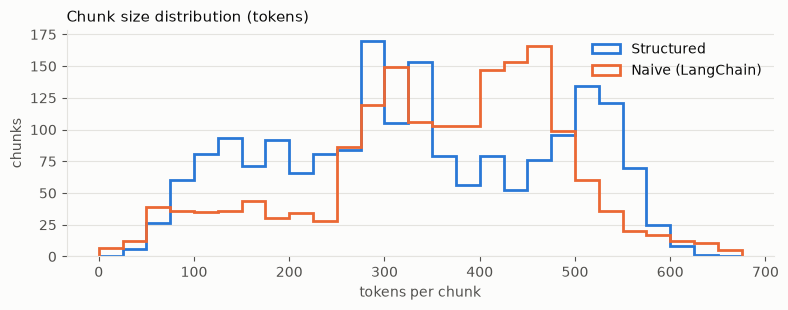

In [6]:
fig, ax = plt.subplots(figsize=(8, 3.2))
bins = range(0, 700, 25)
ax.hist([c["tokens"] for c in chunks], bins=bins, histtype="step", color=BLUE, linewidth=2,
        label="Structured")
ax.hist([c["tokens"] for c in naive], bins=bins, histtype="step", color=ORANGE, linewidth=2,
        label="Naive (LangChain)")
ax.set_title("Chunk size distribution (tokens)", loc="left", fontsize=11, color=INK)
ax.set_xlabel("tokens per chunk"); ax.set_ylabel("chunks")
ax.legend(frameon=False)
plt.tight_layout(); plt.show()

## Step 3 - The synthetic distribution center

*Meridian Consumer Goods - Columbus DC* is fictional, but its hazmat classifications come
from the real 49 CFR 172.101 table. The SQLite database is what the agent's SQL tool will query.

In [7]:
con = sqlite3.connect(DATA_DIR / "dc.db")
q = lambda sql: pd.read_sql_query(sql, con)
tables = [r[0] for r in con.execute("SELECT name FROM sqlite_master WHERE type='table'")]
pd.DataFrame({"table": tables,
              "rows": [con.execute(f'SELECT COUNT(*) FROM "{t}"').fetchone()[0] for t in tables]})

,table,rows
0,zones,8
1,locations,1540
2,skus,43
3,suppliers,7
4,carriers,5
5,customers,7
6,employees,10
7,inventory,561
8,inbound_receipts,408
9,receipt_lines,960


**Exceptions by type and severity** - the history the agent can learn from:

In [8]:
q("SELECT type, severity, COUNT(*) AS n FROM exceptions GROUP BY 1, 2").pivot_table(
    index="type", columns="severity", values="n", fill_value=0)[["high", "medium", "low"]].astype(int)

severity,high,medium,low
type,,,
DAMAGED_INBOUND,0,13,19
FORKLIFT_NEAR_MISS,2,11,0
HAZMAT_SEGREGATION,7,0,0
INVENTORY_MISMATCH,0,0,34
LATE_CARRIER,33,43,0
LEAK_SPILL,9,3,0
MISSING_HAZMAT_MARKING,0,12,0
MISSING_SSCC,0,44,62
QTY_DISCREPANCY,0,0,20


**A planted scenario:** tomorrow's 06:00 trailer to ProClean. Hydrogen peroxide (class 5.1) and
caustic stripper (class 8) are both fully regulated - a 49 CFR 177.848 "O" pair. The drain opener
is a limited quantity, so it does not count. The agent should catch this.

In [9]:
q("""
SELECT s.shipment_id, s.planned_departure, c.name AS customer, k.sku, k.description,
       k.un_number, k.hazard_class,
       CASE k.limited_quantity WHEN 1 THEN 'yes' ELSE 'no' END AS limited_qty
FROM shipments s
JOIN customers c USING (customer_id)
JOIN shipment_lines l USING (shipment_id)
JOIN skus k USING (sku)
WHERE s.shipment_id = 'SHP-01209'
""")

,shipment_id,planned_departure,customer,sku,description,un_number,hazard_class,limited_qty
0,SHP-01209,2026-10-17 06:00,ProClean Janitorial Supply,HPOX-001,CleanPro Hydrogen Peroxide 35% Stabilized 20 L drum,UN2014,5.1,no
1,SHP-01209,2026-10-17 06:00,ProClean Janitorial Supply,CAUS-001,CleanPro Caustic Floor Stripper Heavy Duty 20 L drum,UN1824,8,no
2,SHP-01209,2026-10-17 06:00,ProClean Janitorial Supply,DRNO-001,CleanPro Drain Opener Gel Max Gel 1 L,UN1824,8,yes


## Step 4 - Hybrid retrieval

BM25 keyword search catches exact codes; vector search catches paraphrases; Reciprocal Rank
Fusion combines both. Without an API key these cells use keyword search only.

In [10]:
from copilot.retrieval.retriever import Retriever

embedder = None
if settings.openai_api_key:
    from copilot.retrieval.embeddings import openai_embedder
    embedder = openai_embedder()
retriever = Retriever(chunks, embedder)
MODE = "hybrid" if embedder else "bm25"

def show(question, k=4, **filters):
    hits = retriever.search(question, k=k, mode=MODE, where=filters or None)
    print(f"Q: {question}   [{MODE}]")
    return pd.DataFrame([{"rank": i, "citation": h.chunk["citation"],
                          "snippet": h.chunk["body"][:110].replace("\n", " ")}
                         for i, h in enumerate(hits, 1)])

show("Can pool shock and chlorine tablets go on the same truck?")

Q: Can pool shock and chlorine tablets go on the same truck?   [hybrid]


,rank,citation,snippet
0,1,SOP-HAZ-002 §3,## 3. Key rule: 49 CFR 177.848 segregation table The segregation table in 49 CFR 177.8...
1,2,SDS-TCCA §8-16,"## 8. Exposure controls / personal protection Goggles, rubber gloves, dust respirator...."
2,3,SDS-TCCA §1-7,## 1. Identification - **Product:** AquaShock Chlorine Tablets (TCCA) (20 kg pail) - *...
3,4,SDS-PSHB §7-16,## 7. Handling and storage Handle in accordance with good industrial hygiene. At DC-CO...


In [11]:
show("What protective gear do I need to clean up a drain opener spill?", doc_type="sds")

Q: What protective gear do I need to clean up a drain opener spill?   [hybrid]


,rank,citation,snippet
0,1,SDS-DRNO §1-10,## 1. Identification - **Product:** CleanPro Drain Opener Gel (1 L) - **Product family...
1,2,SDS-DRNO §11-16,"## 11. Toxicological information Corrosive: severe burns to skin, eyes and digestive t..."
2,3,SDS-LQD §1-10,"## 1. Identification - **Product:** Brightwash Liquid Laundry Detergent (1.47 L, 2.95 ..."
3,4,SDS-PSHB §1-6,## 1. Identification - **Product:** AquaShock Pool Shock Bulk Pail (25 kg pail) - **Pr...


### Retrieval evaluation

42 golden questions, phrased the way DC staff would ask them. A hit means a chunk containing the
known evidence phrase is in the top 5. Re-run `python -m copilot.eval.retrieval_eval` to refresh.

In [12]:
results = pd.DataFrame(json.loads((DATA_DIR / "eval" / "results" / "retrieval.json").read_text()))
results[["strategy", "mode", "hit@1", "hit@5", "mrr@10"]].style.format(
    {"hit@1": "{:.0%}", "hit@5": "{:.0%}", "mrr@10": "{:.3f}"}).hide(axis="index")

strategy,mode,hit@1,hit@5,mrr@10
structured,bm25,38%,69%,0.520
structured,vector,64%,88%,0.731
structured,hybrid,62%,81%,0.701
naive,bm25,43%,69%,0.562
naive,vector,60%,81%,0.671
naive,hybrid,60%,86%,0.700


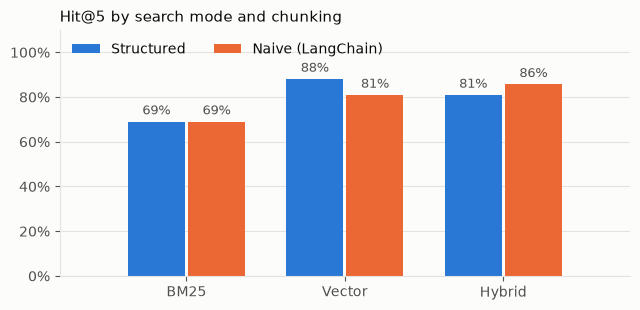

In [13]:
pivot = results.pivot(index="mode", columns="strategy", values="hit@5")
pivot = pivot.loc[[m for m in ["bm25", "vector", "hybrid"] if m in pivot.index]]
fig, ax = plt.subplots(figsize=(6.5, 3.2))
x = list(range(len(pivot)))
w = 0.36
for off, col, color, label in [(-w / 2 - 0.01, "structured", BLUE, "Structured"),
                               (w / 2 + 0.01, "naive", ORANGE, "Naive (LangChain)")]:
    bars = ax.bar([i + off for i in x], pivot[col], width=w, color=color, label=label)
    ax.bar_label(bars, labels=[f"{v:.0%}" for v in pivot[col]], padding=3, color=INK_2, fontsize=9)
ax.set_xticks(x, ["BM25" if m == "bm25" else m.capitalize() for m in pivot.index])
ax.set_xlim(-0.8, len(x) - 0.2); ax.set_ylim(0, 1.1); ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.set_title("Hit@5 by search mode and chunking", loc="left", fontsize=11, color=INK)
ax.legend(frameon=False, loc="upper left", ncols=2)
plt.tight_layout(); plt.show()

## Step 5 - Tools the agent can call

Safety- and compliance-critical decisions are made by **deterministic, tested code**; the LLM
(step 6) only chooses which tool to call and explains the result.

| Tool | What it does |
|---|---|
| `sql_query` | Read-only SQL over the warehouse DB (read-only mode + an authorizer that rejects every non-read operation) |
| `lookup_hazmat` | The official 49 CFR 172.101 Hazardous Materials Table, parsed from the regulation |
| `check_shipment_compliance` | 177.848 segregation (table parsed from the regulation), limited-quantity exception, DC chemical rule, carrier endorsement |
| `assess_departure_risk` | The at-risk rules of SOP-OUT-002 §3 |
| `search_documents` | Step-4 retrieval with collection filters |

In [14]:
import json

from copilot.config import SCENARIOS_PATH
from copilot.tools.shipments import assess_departure_risk, check_shipment_compliance

scenarios = json.loads(SCENARIOS_PATH.read_text())
rows = []
for name in ["seg_conflict_tomorrow", "lq_no_conflict", "carrier_not_hazmat", "at_risk_departure"]:
    sid = scenarios[name]
    c, r = check_shipment_compliance(sid), assess_departure_risk(sid)
    rows.append({"scenario": name, "shipment": sid, "compliant": c["compliant"],
                 "findings": "; ".join(f"{f['severity']}: {f['rule']}" for f in c["findings"]
                                       if f["severity"] != "info") or "-",
                 "at_risk": r["at_risk"]})
pd.DataFrame(rows)

,scenario,shipment,compliant,findings,at_risk
0,seg_conflict_tomorrow,SHP-01209,False,violation: Class 5.1 and 8 require segregation (DC policy: separate trailers),False
1,lq_no_conflict,SHP-01210,True,-,False
2,carrier_not_hazmat,SHP-01211,False,requirement: Calcium hypochlorite and TCCA must never be adjacent; violation: Fully re...,True
3,at_risk_departure,SHP-01212,True,-,True


**The SQL tool is read-only by construction** - writes are rejected by SQLite itself, not by a prompt:

In [15]:
from copilot.tools.sql import sql_query

for query in ["SELECT COUNT(*) FROM shipments WHERE status = 'planned'",
              "DELETE FROM shipments",
              "SELECT 1; DROP TABLE skus"]:
    print(f"{query[:45]:47} -> {sql_query(query)}")

SELECT COUNT(*) FROM shipments WHERE status =   -> {'columns': ['COUNT(*)'], 'rows': [[37]], 'row_count': 1, 'truncated': False}
DELETE FROM shipments                           -> {'error': 'not authorized (this tool is read-only: only SELECT queries are allowed)'}
SELECT 1; DROP TABLE skus                       -> {'error': 'You can only execute one statement at a time.'}


In [16]:
from copilot.tools.hazmat import lookup_hazmat

pd.DataFrame(lookup_hazmat("UN2880")["entries"])[
    ["proper_shipping_name", "hazard_class", "un_number", "packing_group", "label_codes",
     "qty_passenger_aircraft_rail", "qty_cargo_aircraft"]]

,proper_shipping_name,hazard_class,un_number,packing_group,label_codes,qty_passenger_aircraft_rail,qty_cargo_aircraft
0,"Calcium hypochlorite, hydrated or Calcium hypochlorite, hydrated mixture, with not les...",5.1,UN2880,II,5.1,5 kg,25 kg
1,"Calcium hypochlorite, hydrated or Calcium hypochlorite, hydrated mixture, with not les...",5.1,UN2880,III,5.1,25 kg,100 kg


## Step 6 - The agent

A LangGraph loop: the LLM decides which tools to call, reads their results, and answers with
citations that are checked against what the tools returned. Below it handles two planted
scenarios; the tool calls it chose are listed with each answer.

In [17]:
from copilot.agent.graph import Copilot

copilot = Copilot()

def ask(question):
    r = copilot.ask(question)
    print("Q:", question)
    print("tools:", ", ".join(f"{c['name']}({', '.join(map(str, c['args'].values()))})"
                              for c in r.tool_calls))
    print("citations verified:", not r.unverified_citations, "| rewrites:", r.citation_retries)
    print()
    print(r.answer)

ask("Can SHP-01210 go out tomorrow? It has pool shock and bleach on it.")

Q: Can SHP-01210 go out tomorrow? It has pool shock and bleach on it.
tools: check_shipment_compliance(SHP-01210), assess_departure_risk(SHP-01210)
citations verified: True | rewrites: 0

Yes — **SHP-01210 can go out tomorrow**. It is **compliant** for hazmat segregation, and it is **not at risk of a late departure** [49 CFR 177.848(a)] [SOP-OUT-002 §3-4].

Key points:
- Shipment is planned for **2026-10-17 08:00** on **TRL-5120** from **door 16**.
- It carries **pool shock (UN2880, Class 5.1)**, **bleach (UN1791, Class 8)**, and **hand sanitizer (UN1170, Class 3)**.
- All three are marked **limited quantity**, so the segregation table does not apply here [49 CFR 177.848(a)].
- Carrier **Ridgeline Freight** is hazmat-endorsed and has a **96.8% on-time rate** over the last 30 days; the shipment was assessed as **not at risk** [SOP-OUT-002 §3-4].

If you want, I can also pull the line-level shipment details from the warehouse record.


In [18]:
ask("Check SHP-01211 before it leaves.")

Q: Check SHP-01211 before it leaves.
tools: assess_departure_risk(SHP-01211), check_shipment_compliance(SHP-01211)
citations verified: True | rewrites: 0

**SHP-01211 is not clear to leave as planned.** It has a hazmat compliance violation and is at risk of departure delay [SOP-OUT-002 §3.3; SOP-HAZ-002 §4 step 4].

**Findings**
- **Carrier issue:** SHP-01211 is assigned to **Summit Express**, which is **not hazmat-endorsed**; the shipment contains fully regulated hazmat, so it must be reassigned [SOP-HAZ-002 §4 step 4; SOP-OUT-002 §3.3].
- **Load-separation requirement:** The shipment contains **PSHB-001** and **TCCA-001** (both class **5.1**). They **must not be adjacent**; keep them on separate pallets with a non-hazmat pallet or empty space between them, and never in the same overpack [SOP-HAZ-002 §3; SDS section 10].
- **Departure risk:** No trailer is assigned yet, and the shipment is flagged **at risk**. Recommended actions are to confirm trailer/driver ETA, then book a backup c

## Step 7 - Evaluating the agent

36 end-to-end cases, each run 3 times (LLM answers vary). Code checks the tools used,
required citations, key facts and forbidden claims; an LLM judge grades correctness and
completeness against a reference. Re-run with `python -m copilot.eval.agent_eval --repeats 3`.

Pass rate: 93% over 108 answers (36 cases x 3 runs)


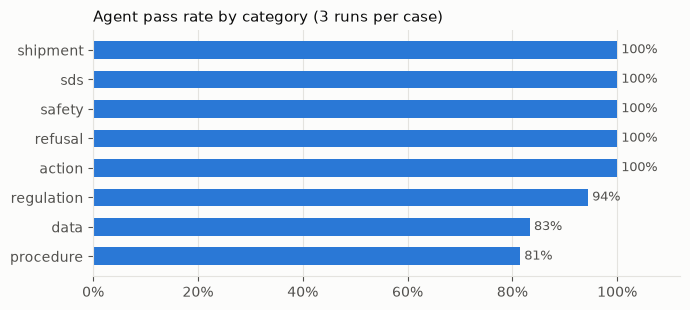

In [19]:
rows = pd.DataFrame(json.loads((DATA_DIR / "eval" / "results" / "agent.json").read_text(encoding="utf-8")))
print(f"Pass rate: {rows['passed'].mean():.0%} over {len(rows)} answers "
      f"({rows['id'].nunique()} cases x {rows['repeat'].nunique()} runs)")
by_cat = rows.groupby("category")["passed"].mean().sort_values()
fig, ax = plt.subplots(figsize=(7, 3.2))
bars = ax.barh(by_cat.index, by_cat.values, color=BLUE, height=0.6)
ax.bar_label(bars, labels=[f"{v:.0%}" for v in by_cat.values], padding=3, color=INK_2, fontsize=9)
ax.set_xlim(0, 1.12); ax.xaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.grid(axis="y", visible=False); ax.grid(axis="x", visible=True)
ax.set_title("Agent pass rate by category (3 runs per case)", loc="left", fontsize=11, color=INK)
plt.tight_layout(); plt.show()

In [20]:
scores = pd.DataFrame(rows["scores"].tolist())
scores.mean().sort_values().to_frame("score").style.format("{:.0%}")

,score
judge_complete,96%
key_facts,97%
citations_valid,99%
required_citation,100%
tool_selection,100%
action,100%
judge_correct,100%
no_forbidden,100%


## What's next

Step 8 puts the agent behind a FastAPI service with a small chat UI, so other systems (and
people) can use it - and every change can be checked against these evaluation scores.